# What is Bivariate Analysis?
- Bivariate Analysis means analyzing the relationship between two variables (columns) in a dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/day36_bivariate_analysis.csv")

In [4]:
df.head()

,Order_ID,City,Category,Marketing_Channel,Customer_Age,Quantity,Unit_Price_INR,Discount_Percent,Customer_Rating,Revenue_INR
0,ORD001,Bengaluru,Furniture,Store,52,3,10937,0,3.5,32811.0
1,ORD002,Chennai,Furniture,Online,40,4,3213,10,2.9,11566.8
2,ORD003,Chennai,Furniture,Online,27,5,10947,0,3.9,54735.0
3,ORD004,Hyderabad,Electronics,Social Media,44,5,5652,15,4.4,24021.0
4,ORD005,Bengaluru,Grocery,Online,33,2,7293,5,3.3,13856.7


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_ID           50 non-null     object 
 1   City               50 non-null     object 
 2   Category           50 non-null     object 
 3   Marketing_Channel  50 non-null     object 
 4   Customer_Age       50 non-null     int64  
 5   Quantity           50 non-null     int64  
 6   Unit_Price_INR     50 non-null     int64  
 7   Discount_Percent   50 non-null     int64  
 8   Customer_Rating    50 non-null     float64
 9   Revenue_INR        50 non-null     float64
dtypes: float64(2), int64(4), object(4)
memory usage: 4.0+ KB


In [7]:
df.describe()

,Customer_Age,Quantity,Unit_Price_INR,Discount_Percent,Customer_Rating,Revenue_INR
count,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000
mean,39.180000,2.820000,7158.860000,9.900000,3.874000,18550.064000
std,13.658652,1.507667,4063.388061,7.456678,0.688035,14186.107959
min,18.000000,1.000000,223.000000,0.000000,2.600000,274.400000
25%,27.000000,1.250000,4273.000000,5.000000,3.300000,8521.350000
50%,38.500000,2.500000,7140.500000,10.000000,3.700000,18106.675000
75%,51.000000,4.000000,10974.000000,15.000000,4.500000,23925.700000
max,60.000000,5.000000,14453.000000,20.000000,4.900000,56800.000000


In [8]:
df.columns

Index(['Order_ID', 'City', 'Category', 'Marketing_Channel', 'Customer_Age',
       'Quantity', 'Unit_Price_INR', 'Discount_Percent', 'Customer_Rating',
       'Revenue_INR'],
      dtype='object')

In [9]:
df.isnull().sum()

Order_ID             0
City                 0
Category             0
Marketing_Channel    0
Customer_Age         0
Quantity             0
Unit_Price_INR       0
Discount_Percent     0
Customer_Rating      0
Revenue_INR          0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

# Numerical vs Numerical
1. Customer Age vs Revenue

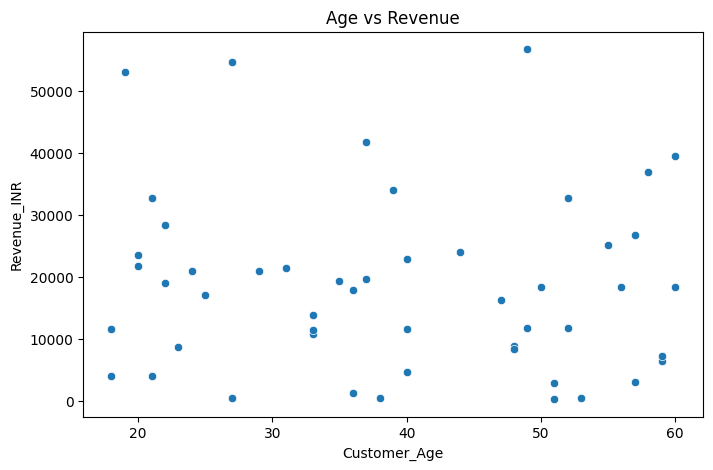

In [11]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Customer_Age", y="Revenue_INR")
plt.title("Age vs Revenue")
plt.show()

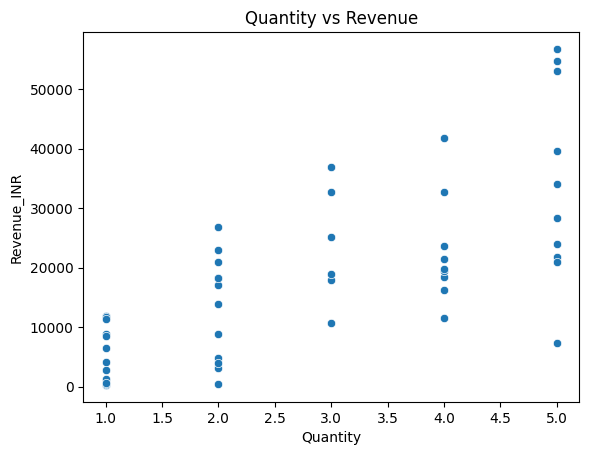

In [12]:
# 2. Quantity vs Revenue
sns.scatterplot(data=df, x="Quantity", y="Revenue_INR")
plt.title("Quantity vs Revenue")
plt.show()

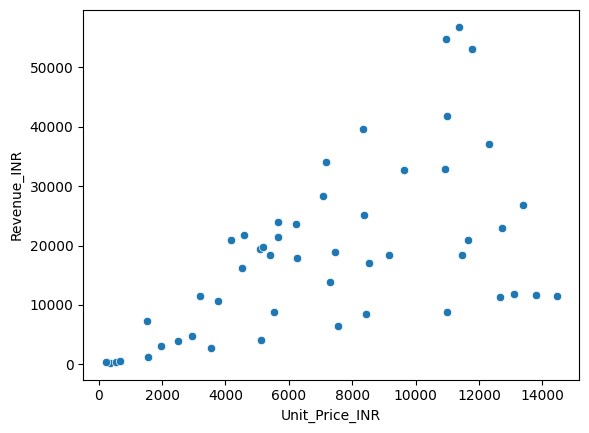

In [13]:
# 3. Unit Price vs Revenue
sns.scatterplot(data=df, x="Unit_Price_INR", y="Revenue_INR")
plt.show()

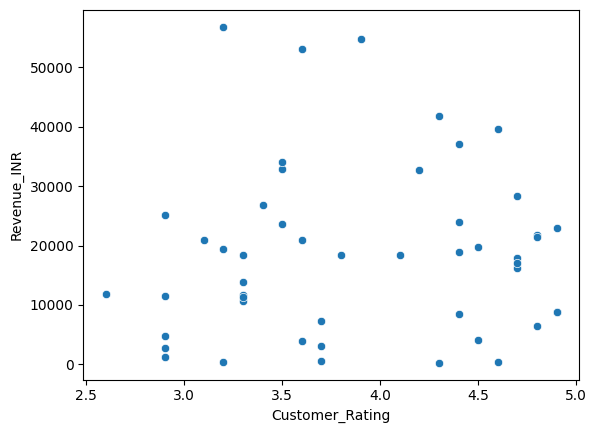

In [14]:
# 4. Customer Rating vs Revenue
sns.scatterplot(data=df, x="Customer_Rating", y="Revenue_INR")
plt.show()

In [15]:
# 5. Correlation between two numerical columns
df["Quantity"].corr(df["Revenue_INR"])

np.float64(0.7013316235749274)

In [16]:
# 6. Correlation between Age and Revenue
df["Customer_Age"].corr(df["Revenue_INR"])

np.float64(-0.07329698824439401)

# Categorical vs Numerical
- 7. Category-wise Revenue

In [17]:
df.groupby("Category")["Revenue_INR"].mean()

Category
Clothing       22351.455556
Electronics    15803.006667
Furniture      21769.217857
Grocery        15377.162500
Name: Revenue_INR, dtype: float64

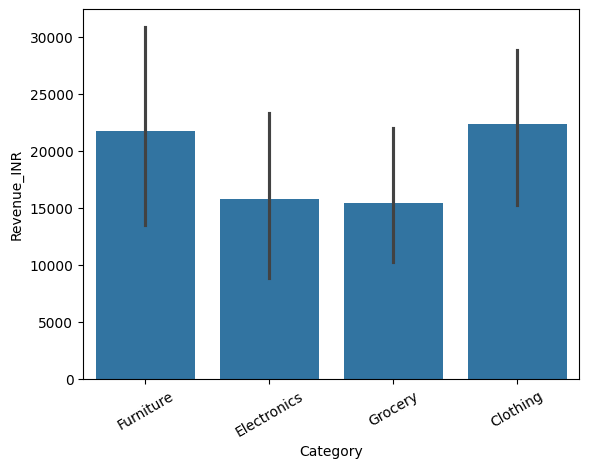

In [18]:
# 8. Category-wise Average Revenue Chart
sns.barplot(data=df, x="Category", y="Revenue_INR")
plt.xticks(rotation=30)
plt.show()

In [19]:
# 9. City-wise Revenue
df.groupby("City")["Revenue_INR"].sum()

City
Bengaluru    310679.30
Chennai      308009.80
Hyderabad    169242.55
Kurnool      139571.55
Name: Revenue_INR, dtype: float64

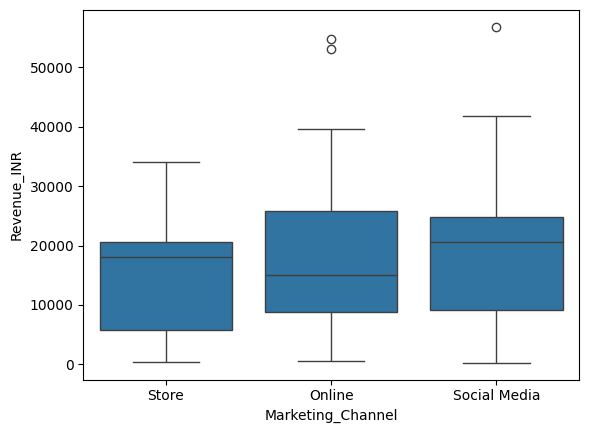

In [20]:
# 10. Marketing Channel vs Revenue
sns.boxplot(data=df, x="Marketing_Channel", y="Revenue_INR")
plt.show()

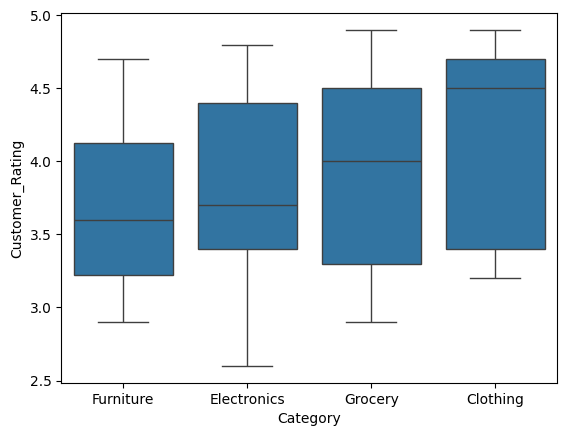

In [21]:
#11. Category vs Customer Rating
sns.boxplot(data=df, x="Category", y="Customer_Rating")
plt.show()

In [22]:
# 12. City-wise Average Customer Rating
df.groupby("City")["Customer_Rating"].mean()

City
Bengaluru    3.618750
Chennai      3.933333
Hyderabad    3.736364
Kurnool      4.462500
Name: Customer_Rating, dtype: float64

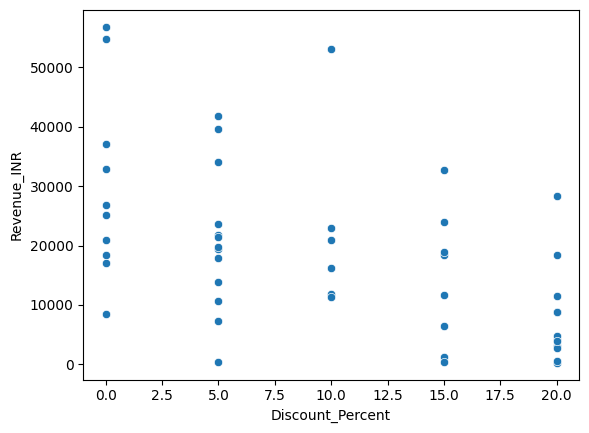

In [23]:
# 13. Discount vs Revenue
sns.scatterplot(data=df, x="Discount_Percent", y="Revenue_INR")
plt.show()

In [24]:
# 14. Average Revenue by Marketing Channel
df.groupby("Marketing_Channel")["Revenue_INR"].mean().sort_values(ascending=False)

Marketing_Channel
Social Media    20977.778571
Online          19002.070455
Store           15412.053571
Name: Revenue_INR, dtype: float64

# Categorical vs Categorical
- 15. City vs Category

In [25]:
pd.crosstab(df["City"], df["Category"])

Category,Clothing,Electronics,Furniture,Grocery
City,,,,
Bengaluru,3,5,6,2
Chennai,2,4,5,4
Hyderabad,2,4,3,2
Kurnool,2,2,0,4


In [26]:
# 16. City vs Marketing Channel
pd.crosstab(df["City"], df["Marketing_Channel"])

Marketing_Channel,Online,Social Media,Store
City,,,
Bengaluru,7,4,5
Chennai,5,5,5
Hyderabad,6,2,3
Kurnool,4,3,1


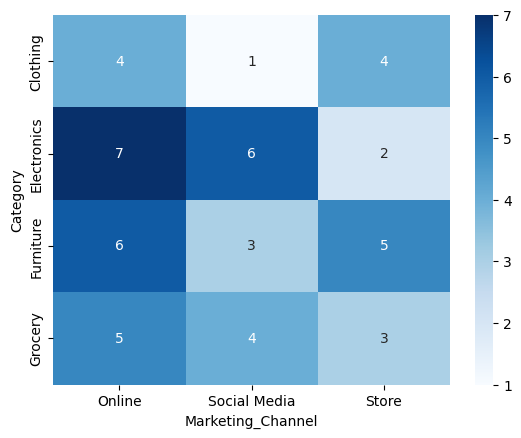

In [27]:
# 17. Category vs Marketing Channel Heatmap
table = pd.crosstab(df["Category"], df["Marketing_Channel"])
sns.heatmap(table, annot=True, cmap="Blues", fmt="d")
plt.show()

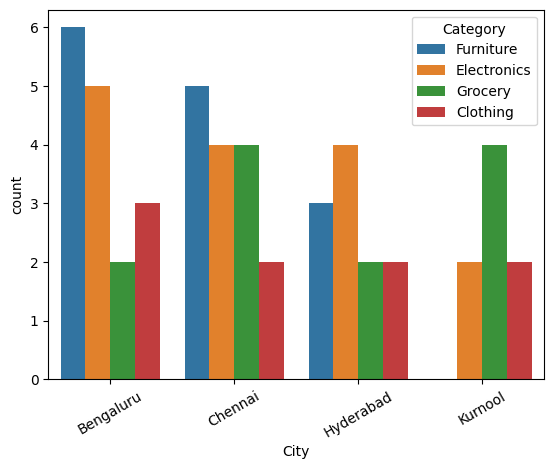

In [28]:
# 18. City vs Category Countplot
sns.countplot(data=df, x="City", hue="Category")
plt.xticks(rotation=30)
plt.show()

# Advanced Analysis
- 19. Correlation Heatmap

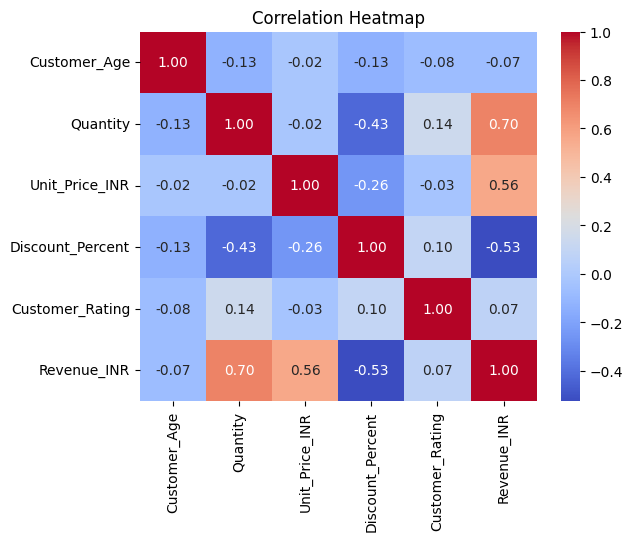

In [29]:
numeric_df = df.select_dtypes(include="number")
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [31]:
# 20. Category-wise Revenue and Quantity
df.groupby("Category").agg(
    Total_Revenue=("Revenue_INR", "sum"),
    Average_Revenue=("Revenue_INR", "mean"),
    Total_Quantity=("Quantity", "sum"))

,Total_Revenue,Average_Revenue,Total_Quantity
Category,,,
Clothing,201163.10,22351.455556,33
Electronics,237045.10,15803.006667,38
Furniture,304769.05,21769.217857,43
Grocery,184525.95,15377.162500,27


# Important concepts
- Positive correlation: One variable increases, the other also tends to increase.
- Negative correlation: One variable increases, the other tends to decrease.
- Zero or weak correlation: No clear linear relationship.
- Scatter plot: Shows the relationship between two numerical variables.
- Boxplot: Compares numerical distributions across categories.
- Heatmap: Displays values or correlations using colors.